<a href="https://colab.research.google.com/github/vegeraj/Basic-dictionary/blob/master/FashionMNIST_vezetett_labor_vizualis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FashionMNIST – képosztályozás, tanulási görbék és hibák elemzése

**Vezetett labor | PyTorch | Google Colab | CPU**

**A labor végére képes leszel:**

1. Beolvasni és megjeleníteni képosztályozási adatokat.
2. Egyszerű, teljesen összekapcsolt neurális hálózatot tanítani.
3. Értelmezni a tanítási és validációs veszteség-, illetve pontossággörbéket.
4. Tévesztési mátrix és konkrét képek alapján elemezni a modell hibáit.
5. Elválasztani a **hiperparaméter-választást** (validáció) a **végső teljesítményméréstől** (teszt).

**Futtatás:** Google Colab → *Fájl → Jegyzetfüzet feltöltése* → válaszd ezt az `.ipynb` fájlt → *Futtatókörnyezet → Összes futtatása*. CPU elegendő; nincs szükség GPU-ra, külön telepítésre általában nincs szükség. Az első futtatás internetkapcsolattal letölti az adatokat. A teljes futási idő a Colab CPU-jától függ.

> **Módszertani szabály:** 54 000 tanítókép + 6 000 validációs kép a fejlesztéshez, 10 000 tesztkép csak a legvégén. A tesztpéldákon végzett utólagos hibaelemzés **nem** szolgál további modellhangolásra.

## 1. Importok és reprodukálhatóság

A `manual_seed(42)` rögzíti a véletlengenerátor magját; a választott szám önkényes. A `ToTensor()` az eredeti képet 0 és 1 közötti értékeket tartalmazó tensorrá alakítja. Egy kép alakja `[1, 28, 28]` (csatorna, magasság, szélesség).

Az ábrák a Matplotlib segítségével jelennek meg.

In [13]:
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
device = torch.device("cpu")  # A labor CPU-ra készült.

plt.rcParams["font.family"] = "DejaVu Sans"

CLASS_NAMES = [
    "Póló/felső", "Nadrág", "Pulóver", "Ruha", "Kabát",
    "Szandál", "Ing", "Sportcipő", "Táska", "Bokacsizma"
]

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("Eszköz:", device)

PyTorch: 2.11.0+cpu
TorchVision: 0.26.0+cpu
Eszköz: cpu


## 2. Az adatok letöltése, felosztása és ellenőrzése

A **FashionMNIST** 70 000 szürkeárnyalatos képet tartalmaz. A tanító (54 000) és validációs (6 000) halmazt az eredeti 60 000-es tanítókészletből képezzük; a 10 000-es teszthalmaz külön marad.

A `batch_size=64` azt jelenti, hogy a modell tanítás közben egyszerre legfeljebb 64 képet dolgoz fel. A `shuffle=True` összekeveri a tanítómintákat.

In [14]:
transform = transforms.ToTensor()

full_train = datasets.FashionMNIST(
    root="data", train=True, download=True, transform=transform
)
test_set = datasets.FashionMNIST(
    root="data", train=False, download=True, transform=transform
)

train_set, valid_set = random_split(
    full_train, [54_000, 6_000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_set, batch_size=64, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
valid_loader = DataLoader(valid_set, batch_size=256, shuffle=False)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)

print(f"Tanítóképek:     {len(train_set):,}")
print(f"Validációs képek: {len(valid_set):,}")
print(f"Tesztképek:      {len(test_set):,}")

X_example, y_example = next(iter(train_loader))
print("Egy batch képeinek alakja:", tuple(X_example.shape))
print("Egy batch címkéinek alakja:", tuple(y_example.shape))
assert X_example.shape == (64, 1, 28, 28)
assert y_example.shape == (64,)

Tanítóképek:     54,000
Validációs képek: 6,000
Tesztképek:      10,000
Egy batch képeinek alakja: (64, 1, 28, 28)
Egy batch címkéinek alakja: (64,)


## 3. Képes adatbemutató: mit „lát” a hálózat?

A következő ábra 16 véletlenszerű, de megismételhetően kiválasztott **tanítóképet** mutat. A felirat a helyes kategória, vagyis a tanításhoz rendelkezésre álló **címke**.

**Megfigyelési feladat:** Mely kategóriák hasonlítanak egymásra? Milyen részletességet veszítünk el a 28×28-as felbontás miatt?

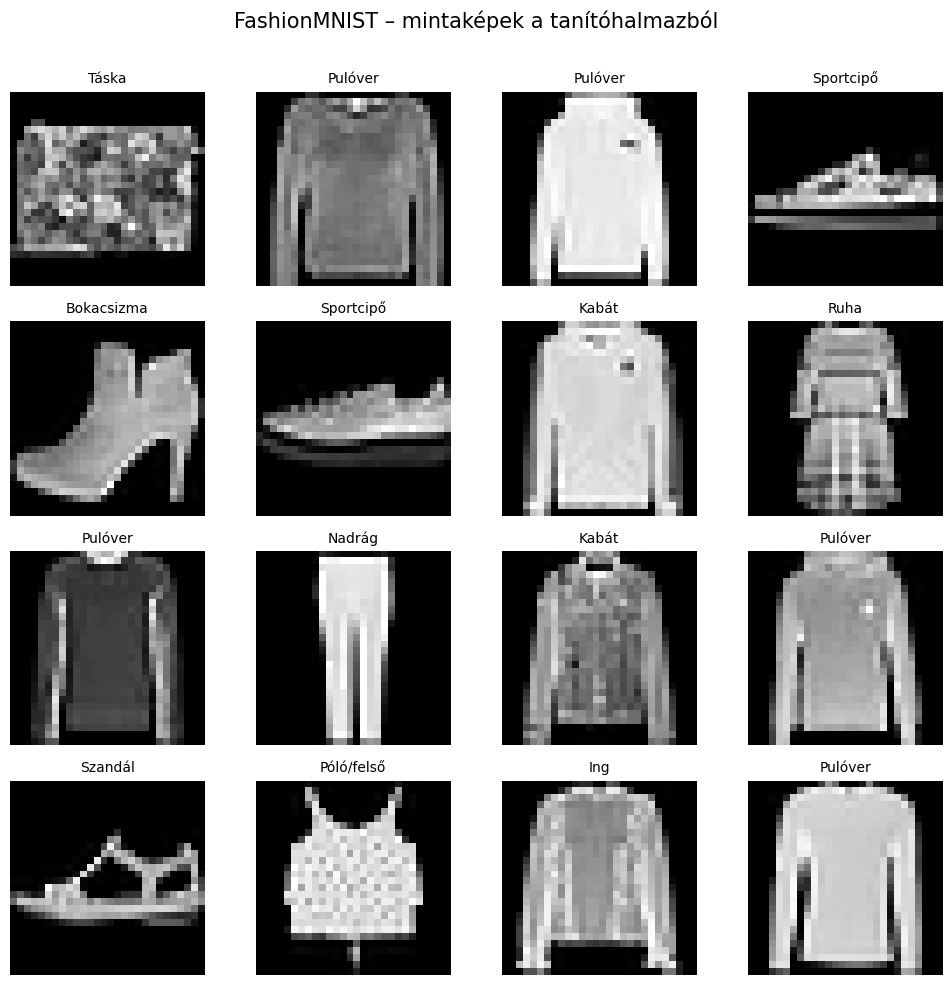

In [15]:
gallery_indices = torch.randperm(
    len(train_set), generator=torch.Generator().manual_seed(SEED)
)[:16].tolist()

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax, index in zip(axes.flat, gallery_indices):
    image, label = train_set[index]
    ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[label], fontsize=10)
    ax.axis("off")

fig.suptitle("FashionMNIST – mintaképek a tanítóhalmazból", fontsize=15)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

## 4. Neurális hálózat definiálása

A `Flatten` a 28×28-as képet **784 hosszúságú vektorrá** lapítja. Az első lineáris réteg 128 rejtett neuront használ, a `ReLU` nemlinearitást vezet be, a második lineáris réteg pedig 10 kimeneti értéket (**logitot**) számít.

A **logit** még nem valószínűség: egy kategóriához tartozó nyers pontszám. A `CrossEntropyLoss` közvetlenül logitokat vár, ezért a modell végére **nem** teszünk `Softmax` réteget. A tanulási ráta (`lr`) meghatározza, mekkorát változhatnak a súlyok egy optimalizációs lépésben.

In [16]:
class ClothingNet(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 10)
        )

    def forward(self, x):
        return self.network(x)


HIDDEN = 128
LEARNING_RATE = 0.1
EPOCHS = 3

model = ClothingNet(hidden=HIDDEN).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)

parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Tanulható paraméterek száma: {parameter_count:,}")

ClothingNet(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Tanulható paraméterek száma: 101,770


## 5. Tanítás és értékelés

Minden tanítóbatch öt lépése: **(1)** korábbi gradiensek törlése, **(2)** előrehaladás a hálózaton, **(3)** veszteség számítása, **(4)** gradiens számítása visszaterjesztéssel, **(5)** súlyfrissítés SGD-vel.

- A **veszteség** a modell kimenete és a helyes címke közötti eltérést számszerűsíti; alacsonyabb általában jobb.
- A **pontosság** a helyesen besorolt minták aránya.
- Értékeléskor nincs súlyfrissítés, `model.eval()` és `torch.no_grad()` használatával.

A teszt végső kiértékelésénél a függvény a helyes és becsült címkéket, valamint a legvalószínűbbnek ítélt osztály Softmax-pontszámát is visszaadhatja. Ezekre a későbbi hibavizsgálathoz van szükség.

In [17]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()

        batch_count = X.size(0)
        total_loss += loss.item() * batch_count
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += batch_count

    return total_loss / total, correct / total


def evaluate(model, loader, loss_fn, device, collect_predictions=False):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    all_true, all_pred, all_conf = [], [], []

    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            predictions = logits.argmax(dim=1)
            batch_count = X.size(0)

            total_loss += loss_fn(logits, y).item() * batch_count
            correct += (predictions == y).sum().item()
            total += batch_count

            if collect_predictions:
                # Softmax csak a kimenet értelmezéséhez kell, nem a veszteséghez.
                confidence = torch.softmax(logits, dim=1).max(dim=1).values
                all_true.append(y.cpu())
                all_pred.append(predictions.cpu())
                all_conf.append(confidence.cpu())

    result = (total_loss / total, correct / total)
    if collect_predictions:
        return (*result, torch.cat(all_true), torch.cat(all_pred), torch.cat(all_conf))
    return result

## 6. Tanítás: három epoch, a legjobb modell mentése

**Epoch:** a teljes tanítóhalmaz egyszeri feldolgozása. Minden epoch után validálunk. A legkisebb validációs veszteséget adó hálózati állapotot mentjük.

A `history` szótárba elmentjük az adatokat a **tanulási görbék** elkészítéséhez. A tanítási mutatók batchenként, tanulás közben keletkeznek; a validációs mutatók az epoch végén, már rögzített súlyokkal számolódnak.

In [18]:
history = {
    "train_loss": [], "train_acc": [],
    "valid_loss": [], "valid_acc": []
}

best_valid_loss = float("inf")
best_epoch = None
MODEL_PATH = "best_fashionmnist_model.pt"

print("Epoch | Tanító veszteség | Valid. veszteség | Tanító pontosság | Valid. pontosság")
print("-" * 83)

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, loss_fn, optimizer, device
    )
    valid_loss, valid_acc = evaluate(model, valid_loader, loss_fn, device)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["valid_loss"].append(valid_loss)
    history["valid_acc"].append(valid_acc)

    print(
        f"{epoch:5d} | {train_loss:15.4f} | {valid_loss:15.4f} | "
        f"{train_acc:15.2%} | {valid_acc:15.2%}"
    )

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        best_epoch = epoch
        torch.save(model.state_dict(), MODEL_PATH)

print(f"\nLegjobb modell: {best_epoch}. epoch, validációs veszteség: {best_valid_loss:.4f}")
print(f"Mentett modell: {MODEL_PATH}")

Epoch | Tanító veszteség | Valid. veszteség | Tanító pontosság | Valid. pontosság
-----------------------------------------------------------------------------------
    1 |          0.6467 |          0.4969 |          77.33% |          82.72%
    2 |          0.4471 |          0.4152 |          83.99% |          85.32%
    3 |          0.4023 |          0.3981 |          85.64% |          86.32%
    4 |          0.3765 |          0.3833 |          86.41% |          86.25%
    5 |          0.3556 |          0.3803 |          87.12% |          86.07%
    6 |          0.3409 |          0.3642 |          87.69% |          86.50%
    7 |          0.3273 |          0.3923 |          88.21% |          85.68%
    8 |          0.3189 |          0.3681 |          88.43% |          87.02%

Legjobb modell: 6. epoch, validációs veszteség: 0.3642
Mentett modell: best_fashionmnist_model.pt


## 7. Tanulási görbék – láthatóvá válik a fejlődés

**Veszteséggörbe:** az x tengely az epochok száma, az y tengely az átlagos keresztentrópia-veszteség. A kisebb érték kedvezőbb.

**Pontossággörbe:** azt mutatja, hogy a minták hány százalékát sorolta helyes kategóriába a hálózat.

Ha a tanítási eredmény tovább javul, miközben a validációs eredmény romlik, az **túlilleszkedés** jele lehet. Három epoch még kevés lehet a jelenség megfigyeléséhez; a 9. részben 8 epochra bővítheted a tanítást.

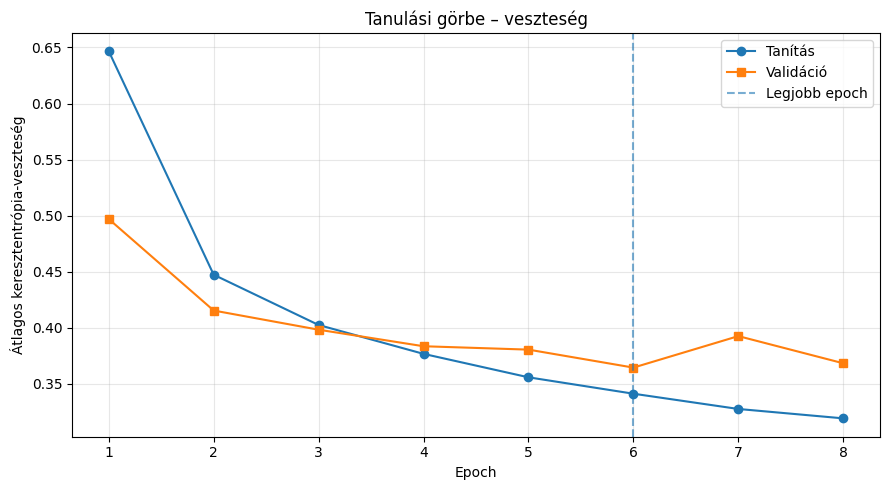

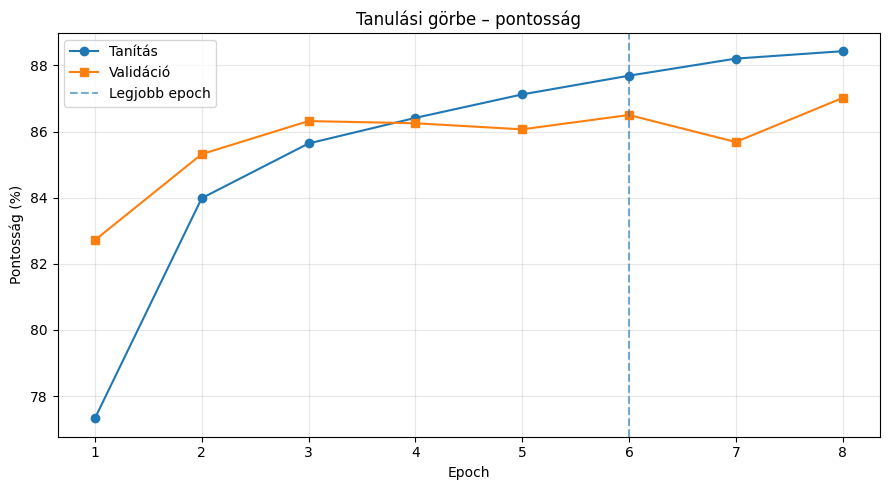

In [19]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs, history["train_loss"], "o-", label="Tanítás")
plt.plot(epochs, history["valid_loss"], "s-", label="Validáció")
plt.axvline(best_epoch, linestyle="--", alpha=0.6, label="Legjobb epoch")
plt.xticks(list(epochs))
plt.xlabel("Epoch")
plt.ylabel("Átlagos keresztentrópia-veszteség")
plt.title("Tanulási görbe – veszteség")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(epochs, [100 * a for a in history["train_acc"]], "o-", label="Tanítás")
plt.plot(epochs, [100 * a for a in history["valid_acc"]], "s-", label="Validáció")
plt.axvline(best_epoch, linestyle="--", alpha=0.6, label="Legjobb epoch")
plt.xticks(list(epochs))
plt.xlabel("Epoch")
plt.ylabel("Pontosság (%)")
plt.title("Tanulási görbe – pontosság")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Végső teszt – pontosan egyszer

A legkisebb validációs veszteségű modellt töltjük vissza. Ezen a ponton **befejeződött a modellválasztás**; most következik a korábban nem használt 10 000 tesztkép kiértékelése.

A további ábrák **ugyanennek az egy tesztkiértékelésnek a mentett jóslatait** használják, tehát nem futtatunk újabb teszteket a különböző grafikonokhoz.

In [20]:
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)

test_loss, test_acc, y_true, y_pred, confidence = evaluate(
    model, test_loader, loss_fn, device, collect_predictions=True
)

assert len(y_true) == len(test_set) == 10_000

print(f"Végső tesztveszteség: {test_loss:.4f}")
print(f"Végső tesztpontosság: {test_acc:.2%}")
print(f"Helyesen besorolt képek: {(y_true == y_pred).sum().item():,} / {len(y_true):,}")
print(f"Hibásan besorolt képek: {(y_true != y_pred).sum().item():,}")

Végső tesztveszteség: 0.3925
Végső tesztpontosság: 85.77%
Helyesen besorolt képek: 8,577 / 10,000
Hibásan besorolt képek: 1,423


## 9. Tévesztési mátrix: mely kategóriákat keveri a modell?

A **tévesztési mátrix** sorai a **valódi kategóriákat**, oszlopai a **megjósolt kategóriákat** jelölik. A főátló a helyes besorolásokat tartalmazza. Például a „Pulóver” sor és az „Ing” oszlop metszetében lévő szám azt mutatja, hogy a valódi pulóverek közül mennyit sorolt ingnek a modell.

Az ábrán **soronként normalizált százalékokat** jelenítünk meg. A számokat a teljes teszthalmazon kapott jóslatokból számoljuk, külső elemzőkönyvtár nélkül.

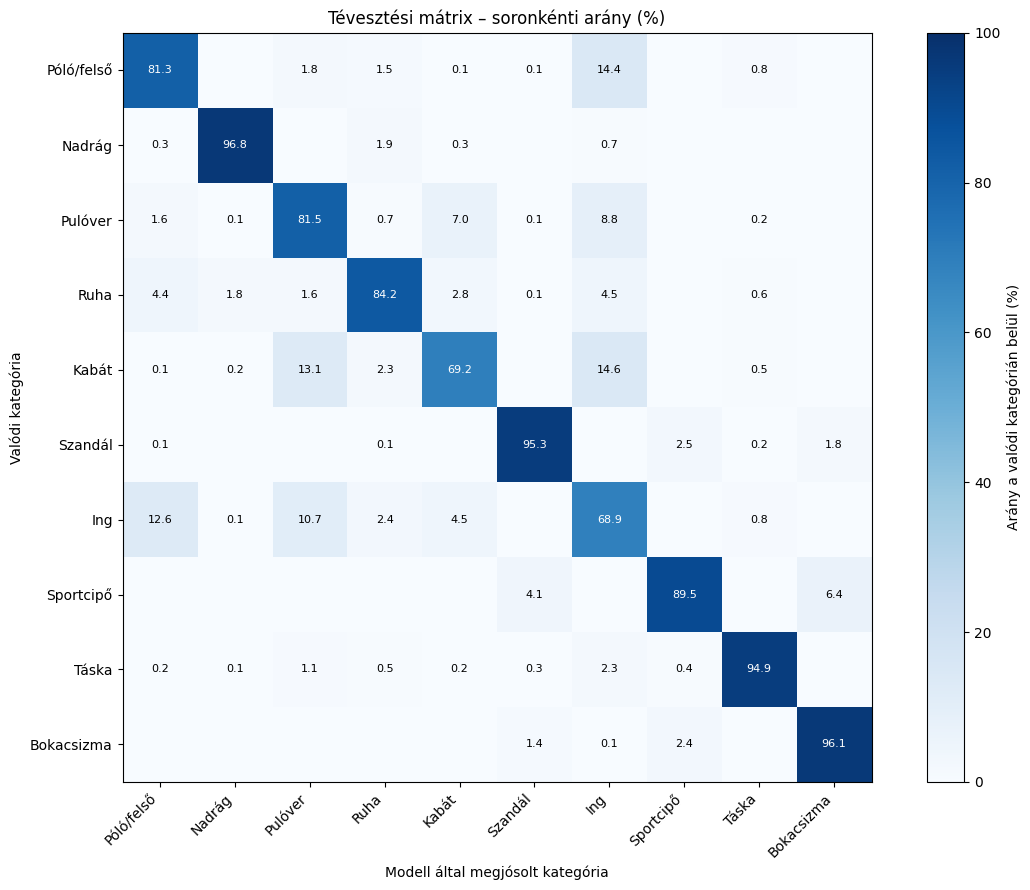

In [21]:
num_classes = len(CLASS_NAMES)
confusion = torch.bincount(
    y_true * num_classes + y_pred,
    minlength=num_classes * num_classes
).reshape(num_classes, num_classes)

row_counts = confusion.sum(dim=1, keepdim=True).clamp(min=1)
confusion_percent = 100 * confusion.float() / row_counts

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(confusion_percent.numpy(), cmap="Blues", vmin=0, vmax=100)

ax.set_xticks(range(num_classes), labels=CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(num_classes), labels=CLASS_NAMES)
ax.set_xlabel("Modell által megjósolt kategória")
ax.set_ylabel("Valódi kategória")
ax.set_title("Tévesztési mátrix – soronkénti arány (%)")

for row in range(num_classes):
    for col in range(num_classes):
        count = int(confusion[row, col].item())
        if count > 0:
            pct = float(confusion_percent[row, col].item())
            ax.text(
                col, row, f"{pct:.1f}", ha="center", va="center",
                fontsize=8, color="white" if pct > 50 else "black"
            )

fig.colorbar(im, ax=ax, label="Arány a valódi kategórián belül (%)")
plt.tight_layout()
plt.show()

### A leggyakoribb tévesztések és kategóriánkénti pontosság

Az alábbi lista megmutatja az öt leggyakoribb **valódi → becsült** tévesztési irányt (az azonos kategóriák kizárásával). Az oszlopdiagram a tíz kategória felismerési arányát ábrázolja.

Az öt leggyakoribb tévesztés:
  Kabát → Ing: 146 kép
  Póló/felső → Ing: 144 kép
  Kabát → Pulóver: 131 kép
  Ing → Póló/felső: 126 kép
  Ing → Pulóver: 107 kép


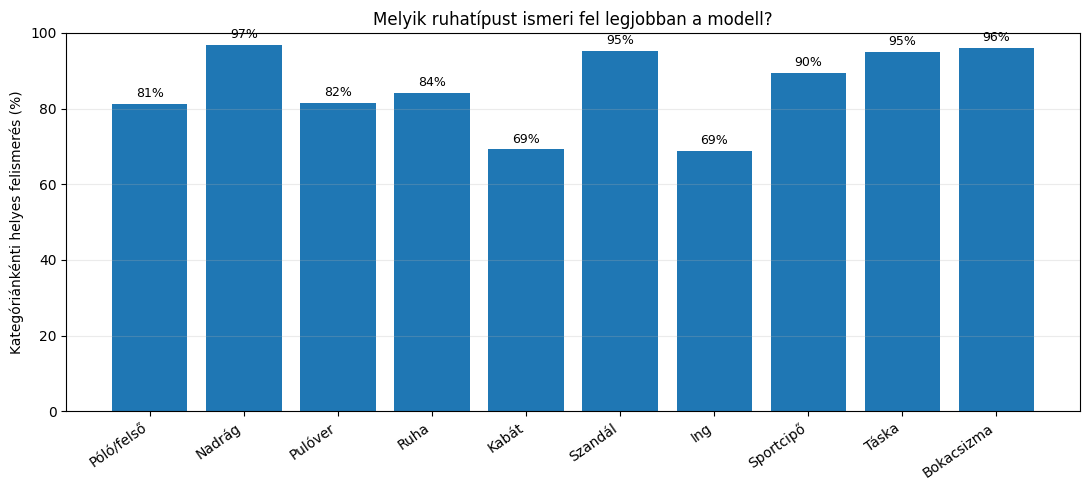

In [22]:
mistakes_only = confusion.clone()
mistakes_only.fill_diagonal_(0)
counts, flat_indices = torch.topk(mistakes_only.flatten(), k=5)

print("Az öt leggyakoribb tévesztés:")
for count, flat_index in zip(counts.tolist(), flat_indices.tolist()):
    true_id = flat_index // num_classes
    pred_id = flat_index % num_classes
    print(f"  {CLASS_NAMES[true_id]} → {CLASS_NAMES[pred_id]}: {count} kép")

class_accuracy = 100 * confusion.diag().float() / confusion.sum(dim=1).clamp(min=1)

plt.figure(figsize=(11, 5))
bars = plt.bar(CLASS_NAMES, class_accuracy.numpy())
plt.ylim(0, 100)
plt.ylabel("Kategóriánkénti helyes felismerés (%)")
plt.title("Melyik ruhatípust ismeri fel legjobban a modell?")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.25)
for bar, score in zip(bars, class_accuracy.tolist()):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
             f"{score:.0f}%", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

## 10. Hibás felismerések képekkel – magabiztos tévedések

Az ábra a teszthalmaz azon **legmagasabb Softmax-pontszámú** hibáit mutatja, amelyeknél a hálózat rossz kategóriát választott. Minden képhez kiírjuk:

- a **valódi címkét**;
- a modell **téves tippjét**;
- a tipphez tartozó **Softmax-pontszámot** százalékban.

**Fontos:** a Softmax-pontszám nem feltétlenül megbízható, kalibrált valószínűsége annak, hogy a modellnek igaza van. Egy modell nagy pontszámmal is tévedhet.

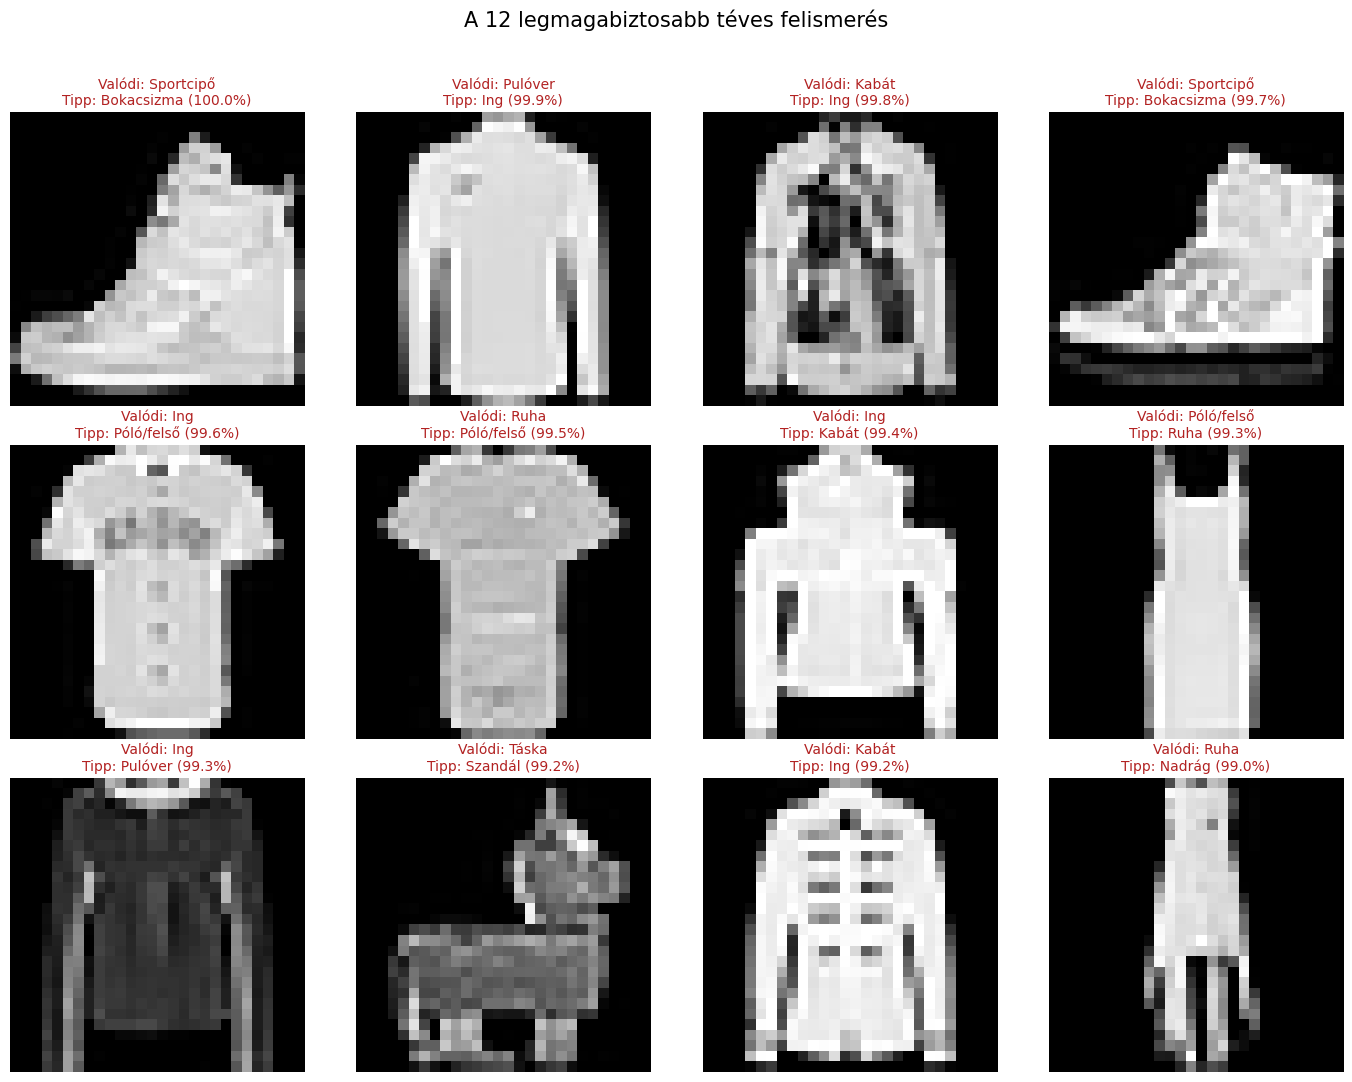

In [23]:
wrong_indices = torch.where(y_true != y_pred)[0]
ranked_wrong = wrong_indices[
    torch.argsort(confidence[wrong_indices], descending=True)
]

show_count = min(12, len(ranked_wrong))
if show_count == 0:
    print("Nem található hibás felismerés a teszthalmazon.")
else:
    fig, axes = plt.subplots(3, 4, figsize=(14, 11))
    for ax in axes.flat:
        ax.axis("off")

    for ax, index in zip(axes.flat, ranked_wrong[:show_count].tolist()):
        image, true_label = test_set[index]
        predicted_label = int(y_pred[index].item())
        score = float(confidence[index].item()) * 100

        ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
        ax.set_title(
            f"Valódi: {CLASS_NAMES[true_label]}\n"
            f"Tipp: {CLASS_NAMES[predicted_label]} ({score:.1f}%)",
            fontsize=10, color="firebrick"
        )
        ax.axis("off")

    fig.suptitle("A 12 legmagabiztosabb téves felismerés", fontsize=15)
    plt.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

## 11. Helyesen felismert tesztképek – összehasonlítás

Nem elég csak a hibákat nézni: a helyes példákat is érdemes megvizsgálni. Itt 12 megismételhetően kiválasztott **helyes** predikció látható. A felirat mellett a becsült kategória Softmax-pontszáma szerepel.

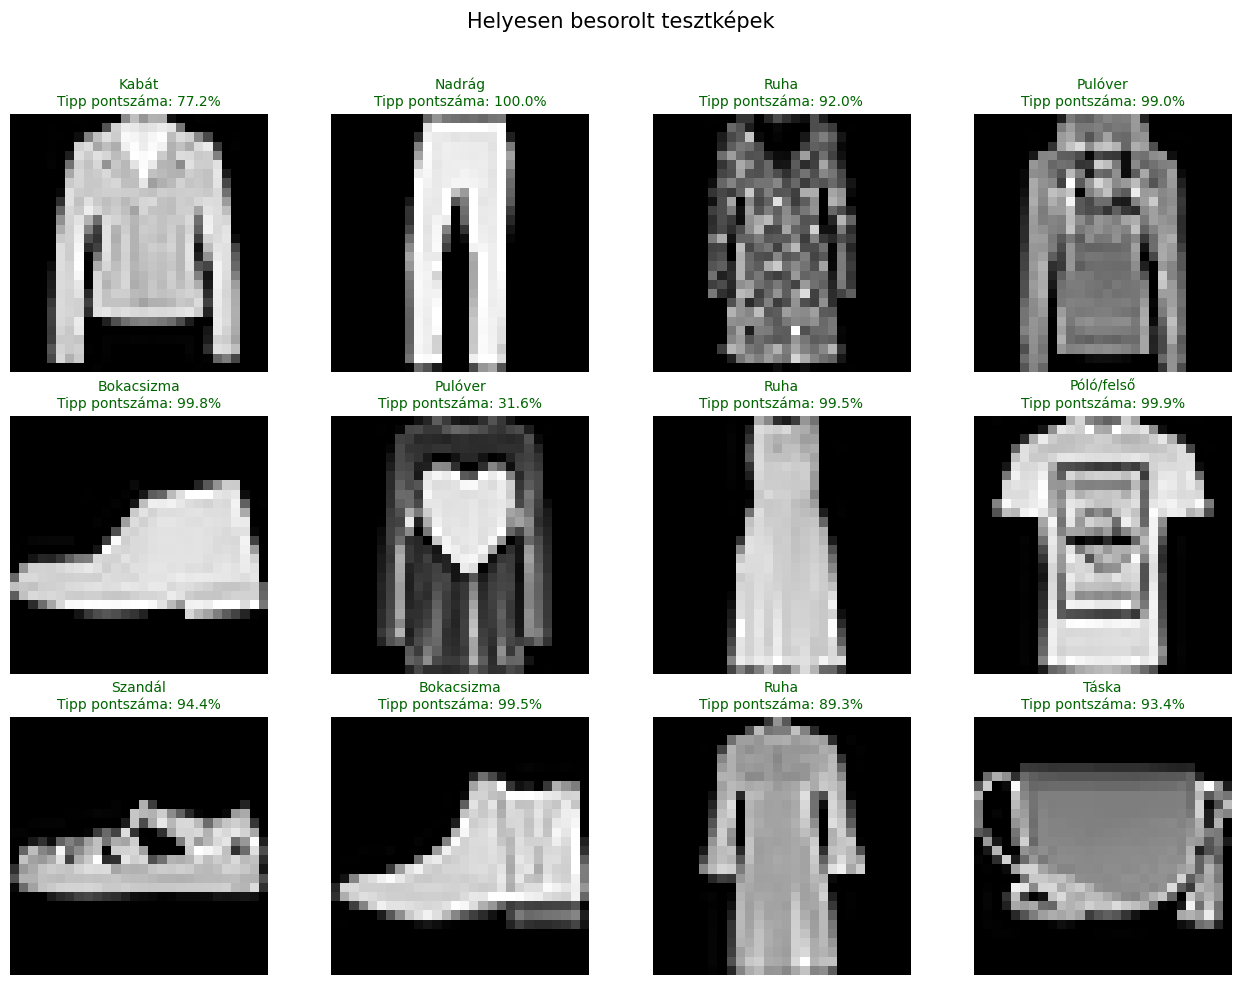

In [24]:
correct_indices = torch.where(y_true == y_pred)[0]
selector = torch.randperm(
    len(correct_indices), generator=torch.Generator().manual_seed(SEED + 1)
)[:12]
selected_correct = correct_indices[selector].tolist()

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax in axes.flat:
    ax.axis("off")

for ax, index in zip(axes.flat, selected_correct):
    image, label = test_set[index]
    ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"{CLASS_NAMES[label]}\nTipp pontszáma: {100 * confidence[index].item():.1f}%",
        fontsize=10, color="darkgreen"
    )
    ax.axis("off")

fig.suptitle("Helyesen besorolt tesztképek", fontsize=15)
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## 12. Kísérletezés – egyszerre egy hiperparamétert változtass!

| Kísérlet | Változtatás | Megfigyelendő jelenség |
|---|---|---|
| A | `HIDDEN = 32` a 128 helyett | Paraméterszám, validációs veszteség és pontosság |
| B | `LEARNING_RATE = 0.01` a 0.1 helyett | Az első három epoch veszteséggörbéje |
| C | Tanító `batch_size=256` a 64 helyett | Súlyfrissítések száma és fejlődési ütem |
| D | `EPOCHS = 8` a 3 helyett | Tanító és validációs görbék eltérése |

**Javasolt kísérleti eljárás:**

1. Az egyes próbák előtt írd le az előzetes jóslatodat.
2. A **tanító- és validációs eredményeket** vesd össze; a tesztet ne használd a paraméterválasztáshoz.
3. Kísérletenként csak egy paramétert módosíts, majd az **összes cellát az elejétől** futtasd újra (különben a korábbi modell súlyai tovább élhetnek).
4. A végleges hiperparamétereket validáció alapján rögzítsd; **csak ezután** következzen a végső teszt.

### Rövid laborbeszámoló – válaszolandó kérdések

- Melyik két ruhakategóriát keverte össze leggyakrabban a modell? Miért lehetnek nehezen megkülönböztethetők?
- Javult-e a validációs veszteség mindhárom epoch után? Melyik epocból töltöttük vissza a modellt?
- A bemutatott hibás példák között van-e olyan, amelyet emberként is nehéz besorolni?
- Miért nem tanácsos a tesztpontosságra optimalizálni a `HIDDEN` vagy `LEARNING_RATE` értékét?
- Miben különböznek egymástól a **tanító**, **validációs** és **teszt** adatok?

> **Kutatásmódszertani megjegyzés:** a teszthalmaz tévesztési mátrixa az elkészült modell hibáinak leírására használható. Ha e hibák alapján újra módosítod a hálózatot, az eredeti teszthalmaz többé nem tekinthető teljesen független végső mérésnek; új, érintetlen tesztadatokra lenne szükség.

**Felhasznált eszközök és adathalmaz:** PyTorch, TorchVision, FashionMNIST, Matplotlib. A notebook nem igényel GPU-t vagy API-kulcsot.